# Mini-projet TIVO : analyse d'un parking par vision par ordinateur
**Filière 3CI-IABD – Semestre 5 – 2026/2027 – Pr. A. Samaké**
Étudiant : `Mohcine Lamtanez` 

## Objectifs (les 6 tâches du sujet)
1. Sélectionner uniquement les voitures **rouges**, puis **blanches**, puis **noires** (techniques classiques, espace HSV).
2. Segmenter l'image en deux zones sémantiques : **surface du parking** et **surface extérieure**.
3. **Détecter et compter** toutes les voitures garées dans le parking (YOLO pré-entraîné, Ultralytics).
4. Déterminer le **nombre total de places disponibles**.
5. Placer un **gros point vert** sur chaque place disponible.
6. **Présenter clairement** les résultats.

## Installation et exécution
```bash
pip install opencv-python numpy matplotlib ultralytics jupyter
# Pillow >= 11.3 lit le format AVIF ; sinon : pip install pillow-avif-plugin
jupyter notebook Mohcine_Lamtanez_mini_projet_TIVO_3CI_IABD_26_27.ipynb
```
Placer dans le **même dossier** que le notebook : l'image `parking_auto.avif` (ou sa version `parking_auto.png`).
Les poids YOLO (`yolo11x-seg.pt`, ~125 Mo) sont téléchargés automatiquement au premier lancement (connexion Internet requise).
Sur un PC sans GPU, l'exécution prend environ une minute ; on peut remplacer par `yolo11m-seg.pt` dans la cellule de configuration (plus rapide, un peu moins précis).
Exécuter ensuite **Kernel → Restart & Run All**.

## Démarche en un coup d'œil
| Étape | Outil | Idée |
|---|---|---|
| Couleurs | OpenCV (HSV, morphologie) | masques de teinte, puis décision **voiture par voiture** |
| Parking / extérieur | OpenCV (HSV + morphologie) | l'extérieur = herbe + bordure, le reste = parking |
| Voitures | Ultralytics YOLO11 | boîtes englobantes, filtrées par la zone parking |
| Places | Repère redressé le long des lignes blanches | grille de places + occupation par les détections YOLO |

## 2. Importation des bibliothèques et configuration

In [5]:
import numpy as np
print(np.__version__)

2.4.6


In [2]:
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

plt.rcParams["figure.dpi"] = 80

# ---------------- Configuration (à adapter si besoin) ----------------
IMAGE_CANDIDATES = ["parking_auto.avif", "parking_auto.png", "parking_auto.jpg"]  # premier fichier trouvé
YOLO_WEIGHTS = "yolo11x-seg.pt"   # YOLO11 COCO pré-entraîné (classe 2 = 'car'), version segmentation : boîtes + contour de chaque voiture
                                  # Alternative plus légère : "yolo11m-seg.pt"
YOLO_IMGSZ   = 1920           # grande résolution : les voitures vues du ciel sont petites par rapport à l'image
YOLO_CONF    = 0.25           # seuil de confiance
YOLO_IOU     = 0.50           # seuil NMS
CURB_WIDTH   = 70             # largeur (px) de la bordure pavée à rattacher à l'extérieur
GREEN_DOT_RADIUS = 30         # rayon (px) des gros points verts

## 3. Chargement et visualisation de l'image

Image : parking_auto.png | 3000 x 1999 pixels | 3 canaux


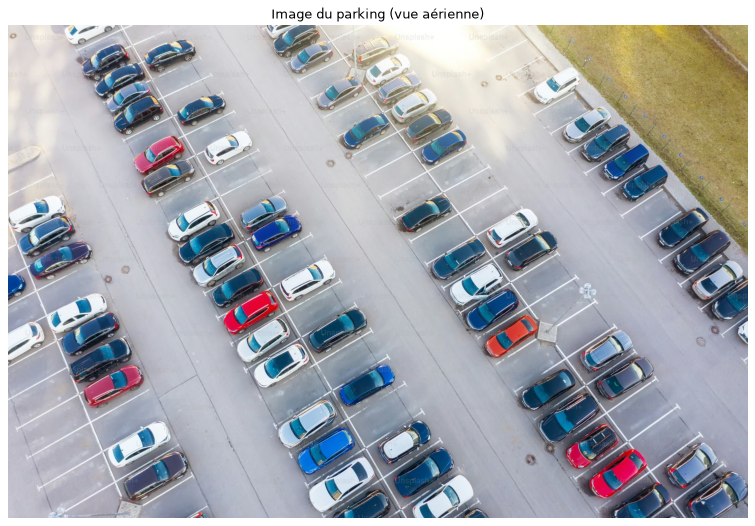

In [3]:
def charger_image(candidats):
    # Charge la première image trouvée (BGR). Repli sur Pillow pour le format AVIF.
    for nom in candidats:
        p = Path(nom)
        if not p.exists():
            continue
        img = cv2.imread(str(p))
        if img is None:
            try:
                from PIL import Image
                try:
                    import pillow_avif  # noqa : nécessaire seulement avec Pillow < 11.3
                except ImportError:
                    pass
                img = cv2.cvtColor(np.array(Image.open(p).convert("RGB")), cv2.COLOR_RGB2BGR)
            except Exception as e:
                print(f"Lecture de {p} impossible : {e}")
        if img is not None:
            return img, p
    raise FileNotFoundError(f"Aucune image trouvée parmi {candidats}. Placez l'image dans le dossier du notebook "
                            "(si le format AVIF pose problème, convertissez-la en PNG).")

img, chemin = charger_image(IMAGE_CANDIDATES)
H_IMG, W_IMG = img.shape[:2]
print(f"Image : {chemin} | {W_IMG} x {H_IMG} pixels | {img.shape[2]} canaux")

def afficher(im_bgr, titre="", taille=(12, 8)):
    plt.figure(figsize=taille)
    plt.imshow(cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB))
    plt.title(titre); plt.axis("off"); plt.show()

afficher(img, "Image du parking (vue aérienne)")

## 4. Préparation et analyse de l'image
On observe : de nombreuses voitures vues du dessus, des **places en épi** délimitées par des lignes blanches,
de l'**herbe** en haut à droite, et une **zone surexposée** (reflet du soleil) en haut au centre.
On passe en **HSV** (Teinte / Saturation / Valeur) après un léger flou gaussien pour réduire le bruit.

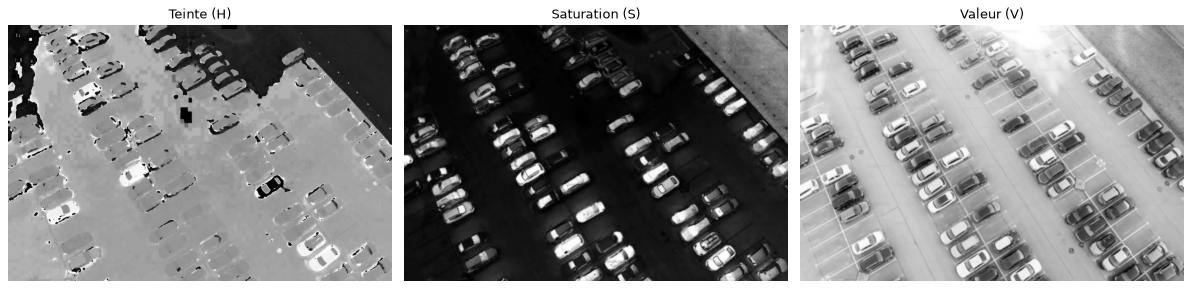

In [4]:
img_blur = cv2.GaussianBlur(img, (0, 0), 3)
hsv = cv2.cvtColor(img_blur, cv2.COLOR_BGR2HSV)   # OpenCV : H in [0,179], S et V in [0,255]
H, S, V = cv2.split(hsv)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, canal, nom in zip(ax, (H, S, V), ("Teinte (H)", "Saturation (S)", "Valeur (V)")):
    a.imshow(canal, cmap="gray"); a.set_title(nom); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Détection des couleurs (méthodes classiques, HSV)
**Principe** : dans HSV, la couleur (teinte) est séparée de la luminosité, ce qui rend les seuils plus robustes aux variations d'éclairage qu'en RGB.

| Couleur | Règle HSV |
|---|---|
| **Rouge** | teinte proche de 0 **ou** de 179 (le rouge « boucle » sur le cercle des teintes → **deux intervalles**), saturation élevée |
| **Blanc** | saturation faible **et** valeur élevée |
| **Noir** | valeur faible (peu importe la teinte) |

On applique ensuite une **ouverture morphologique** (supprime les petits points et les lignes blanches fines) puis une **fermeture** (comble les trous : vitres, reflets).

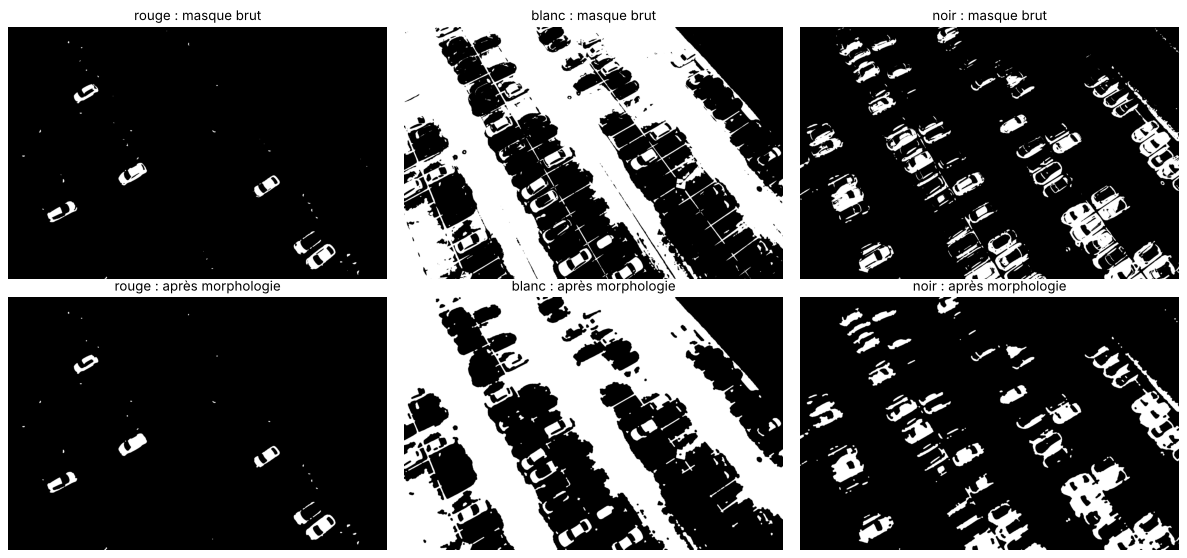

In [4]:
HSV_RANGES = {
    "rouge": [((0, 110, 70), (10, 255, 255)), ((165, 110, 70), (179, 255, 255))],  # deux intervalles de teinte
    "blanc": [((0, 0, 185), (179, 50, 255))],
    # noir : très sombre (V <= 100), ou sombre et peu saturé (V <= 130 et S <= 130) pour les noirs éclairés par le soleil
    "noir":  [((0, 0, 0), (179, 255, 100)), ((0, 0, 101), (179, 130, 130))],
}
KERNEL_OUVERTURE = {"rouge": 7, "blanc": 9, "noir": 9}   # taille (px) de l'élément structurant
KERNEL_FERMETURE = 15

def masque_couleur(hsv_img, intervalles):
    m = np.zeros(hsv_img.shape[:2], np.uint8)
    for bas, haut in intervalles:
        m |= cv2.inRange(hsv_img, np.array(bas), np.array(haut))
    return m

def nettoyer(m, k_ouv, k_fer=KERNEL_FERMETURE):
    ouv = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_ouv, k_ouv))
    fer = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_fer, k_fer))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, ouv)
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, fer)

masques_bruts = {c: masque_couleur(hsv, r) for c, r in HSV_RANGES.items()}
masques = {c: nettoyer(masques_bruts[c], KERNEL_OUVERTURE[c]) for c in HSV_RANGES}

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for j, c in enumerate(HSV_RANGES):
    ax[0, j].imshow(masques_bruts[c], cmap="gray"); ax[0, j].set_title(f"{c} : masque brut"); ax[0, j].axis("off")
    ax[1, j].imshow(masques[c], cmap="gray");        ax[1, j].set_title(f"{c} : après morphologie"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

**Constat important** : un masque de couleur sélectionne des **pixels**, pas des **voitures**.
- Le **blanc** capte aussi le bitume surexposé (haut de l'image) et les lignes de marquage.
- Le **noir** capte les ombres et le bitume humide.

Il faut donc une méthode qui décide **voiture par voiture**. On la met en œuvre en section 8, une fois les voitures localisées :
pour chaque voiture, on mesure quelle proportion de sa zone centrale appartient à chaque masque.

## 6. Segmentation sémantique : surface du parking / surface extérieure
**Méthode** : l'extérieur est ici l'**herbe** (teinte jaune-verte, bien saturée) et la **bordure pavée** qui la longe.
1. Masque HSV de l'herbe (teinte 15–50, saturation ≥ 60) → ouverture/fermeture → plus grande composante connexe.
2. Dilatation de ce masque de `CURB_WIDTH` px pour y rattacher la bordure pavée.
3. **Parking = complément de l'extérieur** (voies de circulation et places comprises).

Polygone du parking (x, y) : [[0, 0], [0, 1998], [2999, 1998], [2999, 997], [2961, 988], [2598, 588], [2107, 70], [2075, 0]]
Surface parking : 91.8 % | extérieur : 8.2 %


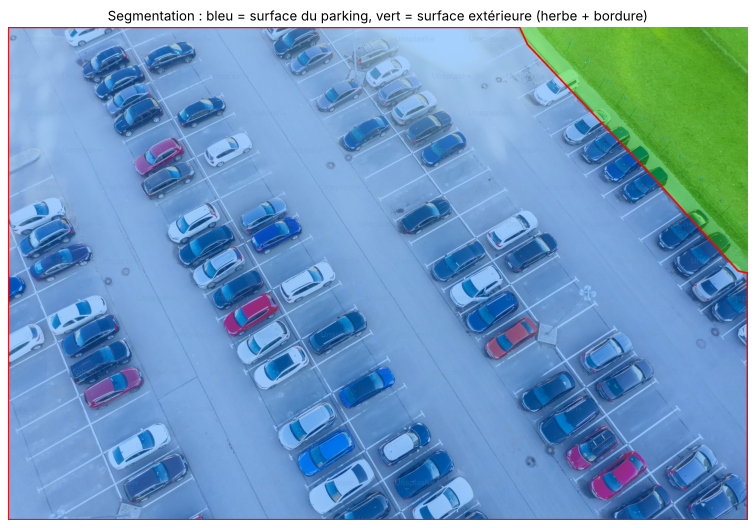

In [5]:
herbe = ((H >= 15) & (H <= 50) & (S >= 60)).astype(np.uint8) * 255
herbe = cv2.morphologyEx(herbe, cv2.MORPH_OPEN,  cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25)))
herbe = cv2.morphologyEx(herbe, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (61, 61)))
n, labels, stats, _ = cv2.connectedComponentsWithStats(herbe)
herbe = (labels == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])).astype(np.uint8) * 255   # plus grande composante

k = 2 * CURB_WIDTH + 1
exterieur = cv2.dilate(herbe, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
masque_parking = cv2.bitwise_not(exterieur)

# Polygone de la zone parking (coordonnées lisibles / configurables)
cnts, _ = cv2.findContours(masque_parking, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
polygone_parking = cv2.approxPolyDP(max(cnts, key=cv2.contourArea), 8, True).reshape(-1, 2)
print("Polygone du parking (x, y) :", polygone_parking.tolist())
print(f"Surface parking : {masque_parking.mean()/255*100:.1f} % | extérieur : {exterieur.mean()/255*100:.1f} %")

overlay = img.copy()
overlay[masque_parking > 0] = (0.65 * overlay[masque_parking > 0] + 0.35 * np.array([255, 120, 0])).astype(np.uint8)  # bleu
overlay[exterieur > 0]      = (0.55 * overlay[exterieur > 0]      + 0.45 * np.array([0, 200, 0])).astype(np.uint8)    # vert
cv2.polylines(overlay, [polygone_parking.reshape(-1, 1, 2)], True, (0, 0, 255), 6)
afficher(overlay, "Segmentation : bleu = surface du parking, vert = surface extérieure (herbe + bordure)")

## 7. Détection et comptage des voitures avec YOLO
**Modèle** : `YOLO11-seg` pré-entraîné sur COCO (classe 2 = `car`), via Ultralytics. Aucun entraînement supplémentaire.
- Inférence en **haute résolution** (`imgsz=1920`) car les voitures vues d'en haut sont petites.
- On récupère les **boîtes englobantes** (utilisées pour compter et pour placer les voitures dans les places) et le **contour** de chaque voiture (utilisé pour mesurer sa couleur).
- On ne garde que les voitures dont le **centre** de boîte est dans la zone parking (section 6).

Voitures détectées au total        : 79
Voitures dans le parking (comptées): 79
Voitures à l'extérieur (ignorées)  : 0
Confiance min / moyenne            : 0.47 / 0.93


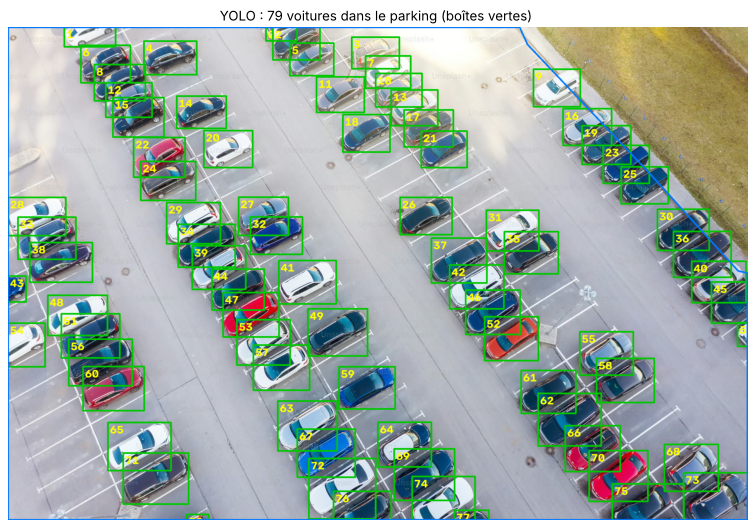

In [6]:
def contour_propre(poly):
    # Les contours YOLO ont parfois de fines pointes dans les rangées denses : ouverture morphologique puis plus grand contour
    poly = np.round(poly).astype(np.int32)
    x1, y1 = np.maximum(poly.min(axis=0) - 5, 0)
    x2, y2 = np.minimum(poly.max(axis=0) + 6, [W_IMG, H_IMG])
    m = np.zeros((y2 - y1, x2 - x1), np.uint8)
    cv2.fillPoly(m, [poly - [x1, y1]], 255)
    m_ouvert = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21)))
    if m_ouvert.sum() < 0.5 * m.sum():       # petite voiture coupée par le bord : on garde le contour brut
        m_ouvert = m
    cnts, _ = cv2.findContours(m_ouvert, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return max(cnts, key=cv2.contourArea).reshape(-1, 2) + [x1, y1]

modele = YOLO(YOLO_WEIGHTS)
res = modele.predict(img, imgsz=YOLO_IMGSZ, conf=YOLO_CONF, iou=YOLO_IOU, classes=[2], retina_masks=True, verbose=False)[0]

voitures = []
for b, c, poly in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.conf.cpu().numpy(), res.masks.xy):
    x1, y1, x2, y2 = [int(round(v)) for v in b]
    cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
    dans_parking = bool(masque_parking[min(cy, H_IMG - 1), min(cx, W_IMG - 1)] > 0)
    voitures.append({"box": (x1, y1, x2, y2), "conf": float(c), "centre": (cx, cy), "dans_parking": dans_parking,
                     "poly": contour_propre(poly)})   # contour de la voiture (segmentation)

# Tri stable (haut -> bas) puis numérotation
voitures.sort(key=lambda v: (v["centre"][1], v["centre"][0]))
for i, v in enumerate(voitures):
    v["id"] = i

voitures_parking = [v for v in voitures if v["dans_parking"]]
print(f"Voitures détectées au total        : {len(voitures)}")
print(f"Voitures dans le parking (comptées): {len(voitures_parking)}")
print(f"Voitures à l'extérieur (ignorées)  : {len(voitures) - len(voitures_parking)}")
print(f"Confiance min / moyenne            : {min(v['conf'] for v in voitures):.2f} / {np.mean([v['conf'] for v in voitures]):.2f}")

vis = img.copy()
for v in voitures:
    x1, y1, x2, y2 = v["box"]
    col = (0, 200, 0) if v["dans_parking"] else (0, 0, 255)
    cv2.rectangle(vis, (x1, y1), (x2, y2), col, 5)
    cv2.putText(vis, str(v["id"]), (x1 + 8, y1 + 45), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 255, 255), 4)
cv2.polylines(vis, [polygone_parking.reshape(-1, 1, 2)], True, (255, 120, 0), 5)
afficher(vis, f"YOLO : {len(voitures_parking)} voitures dans le parking (boîtes vertes) ")

## 8. Sélection des voitures rouges, puis blanches, puis noires
Pour sélectionner des **voitures** (et pas seulement des pixels), on combine les deux outils :
pour chaque voiture, on calcule la **proportion de pixels** des masques HSV nettoyés (section 5) à l'intérieur de son **contour** (fourni par YOLO-seg), légèrement **érodé** pour ne pas toucher le bitume ni les voitures voisines.
Une voiture reçoit la première couleur dont la proportion dépasse le seuil, dans l'ordre **rouge → blanc → noir**.

Les seuils tiennent compte de la carrosserie : une voiture blanche a des vitres sombres (donc seuil blanc ≈ 0,30, pas 0,80), et une voiture noire a des reflets (seuil noir ≈ 0,45).
Les voitures qui ne dépassent aucun seuil (bleues, grises, argentées…) sont rangées dans « autre ».

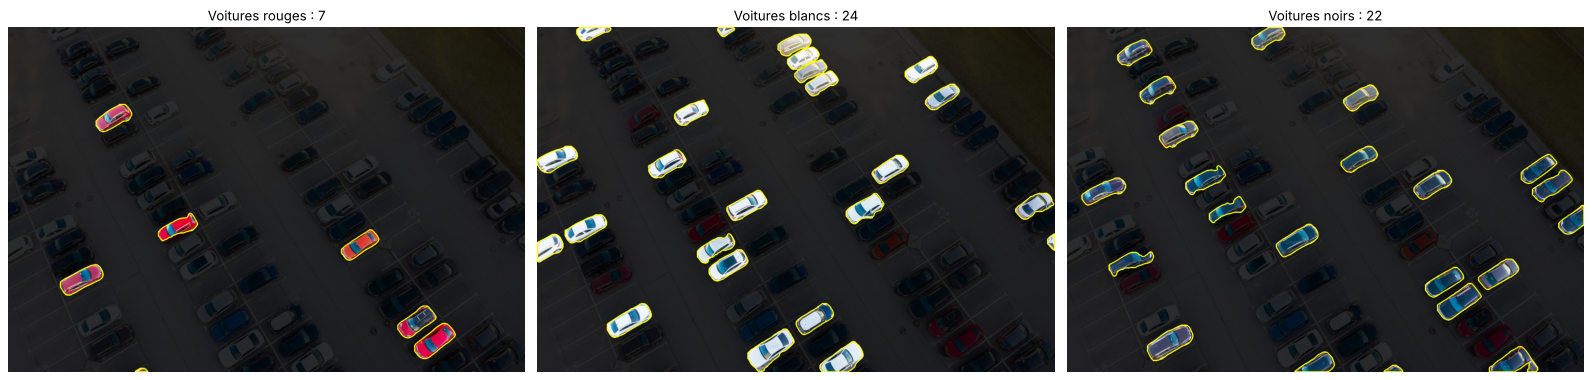

 rouge :  7 voitures  -> identifiants [22, 47, 52, 60, 66, 70, 78]
 blanc : 24 voitures  -> identifiants [0, 1, 3, 7, 9, 10, 13, 16, 20, 28, 29, 31, 40, 41, 42, 48, 50, 53, 54, 57, 64, 65, 72, 74]
  noir : 22 voitures  -> identifiants [2, 6, 15, 17, 24, 26, 30, 34, 35, 36, 38, 44, 45, 49, 56, 58, 61, 62, 71, 75, 76, 77]
 autre : 26 voitures  -> identifiants [4, 5, 8, 11, 12, 14, 18, 19, 21, 23, 25, 27, 32, 33, 37, 39, 43, 46, 51, 55, 59, 63, 67, 68, 69, 73]


In [7]:
SEUILS = {"rouge": 0.15, "blanc": 0.30, "noir": 0.45}   # proportion minimale de pixels de la couleur dans la voiture
EROSION = 25                                             # taille (px) de l'érosion du contour

def pixels_voiture(poly):
    # Retourne (fenêtre, masque booléen) des pixels à l'intérieur du contour, légèrement érodé
    x1, y1 = np.maximum(poly.min(axis=0), 0)
    x2, y2 = np.minimum(poly.max(axis=0) + 1, [W_IMG, H_IMG])
    m = np.zeros((y2 - y1, x2 - x1), np.uint8)
    cv2.fillPoly(m, [poly - [x1, y1]], 1)
    e = cv2.erode(m, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (EROSION, EROSION)))
    if e.sum() < 200:                 # voiture très petite (coupée par le bord de l'image) : pas d'érosion
        e = m
    return (slice(y1, y2), slice(x1, x2)), e.astype(bool)

def couleur_voiture(poly):
    fenetre, interieur = pixels_voiture(poly)
    prop = {c: float((masques[c][fenetre][interieur] > 0).mean()) for c in masques}
    for c in ("rouge", "blanc", "noir"):                       # ordre imposé : rouge, puis blanc, puis noir
        if prop[c] >= SEUILS[c]:
            return c, prop
    return "autre", prop

for v in voitures_parking:
    v["couleur"], v["prop"] = couleur_voiture(v["poly"])

COULEURS_BGR = {"rouge": (0, 0, 255), "blanc": (255, 255, 255), "noir": (30, 30, 30), "autre": (0, 200, 0)}

def isoler(couleur):
    # Image où seules les voitures de cette couleur restent visibles (reste assombri)
    ids = [v for v in voitures_parking if v["couleur"] == couleur]
    zone = np.zeros((H_IMG, W_IMG), np.uint8)
    for v in ids:
        cv2.fillPoly(zone, [v["poly"]], 255)                             # uniquement l'intérieur des voitures retenues
    sortie = (img * 0.18).astype(np.uint8)
    sortie[zone > 0] = img[zone > 0]
    for v in ids:
        cv2.polylines(sortie, [v["poly"]], True, (0, 255, 255), 6)
    return sortie, ids

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, c in zip(ax, ("rouge", "blanc", "noir")):
    im_c, ids = isoler(c)
    a.imshow(cv2.cvtColor(cv2.resize(im_c, (1200, 800)), cv2.COLOR_BGR2RGB)); a.axis("off")
    a.set_title(f"Voitures {c}s : {len(ids)}")
plt.tight_layout(); plt.show()

for c in ("rouge", "blanc", "noir", "autre"):
    ids = [v["id"] for v in voitures_parking if v["couleur"] == c]
    print(f"{c:>6} : {len(ids):2d} voitures  -> identifiants {ids}")

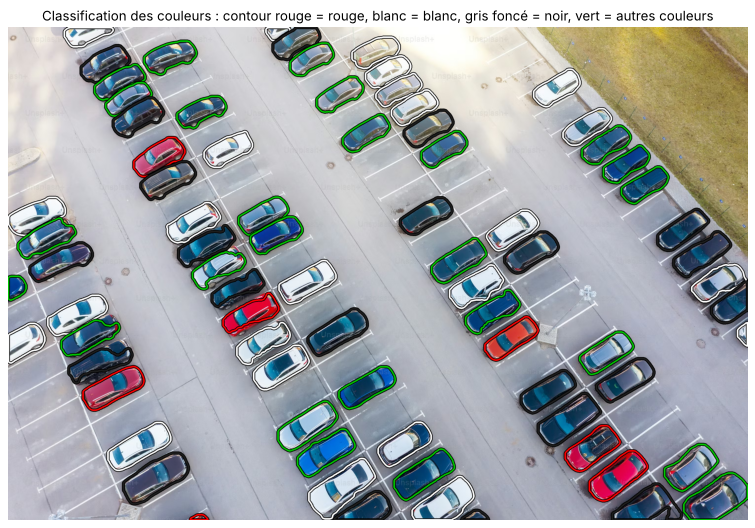

In [8]:
# Vue d'ensemble : chaque voiture encadrée selon sa couleur (rouge / blanc / noir / autre)
vis = img.copy()
for v in voitures_parking:
    cv2.polylines(vis, [v["poly"]], True, (0, 0, 0), 11)
    cv2.polylines(vis, [v["poly"]], True, COULEURS_BGR[v["couleur"]], 6)
afficher(vis, "Classification des couleurs : contour rouge = rouge, blanc = blanc, gris foncé = noir, vert = autres couleurs")

## 9. Identification des places de stationnement et des places disponibles
Les places sont **en épi** (inclinées) et la perspective fait varier leur largeur d'un bout à l'autre du parking. Une grille régulière en pixels serait donc fausse.

**Méthode (analyse réelle de l'image, délimitation manuelle configurable)**
1. Les **longues lignes blanches** qui séparent deux rangées (« axes ») sont repérées par Hough sur le masque des lignes blanches (cellule suivante).
2. Le long de chaque axe, l'image est **redressée** par une transformation affine : dans ce repère `(t, s)`, les séparateurs de places deviennent **horizontaux** et chaque place devient un **rectangle**.
3. Les bornes `t` de chaque place sont **relevées sur les séparateurs blancs visibles**. Quand un véhicule masque un séparateur, la borne est complétée avec le pas local (la largeur des places croît régulièrement avec `t` à cause de la perspective).
4. Les rectangles sont reconvertis en quadrilatères dans l'image d'origine.
5. **Occupation** : une place est occupée si le **centre d'une boîte YOLO** tombe dans son quadrilatère. Les autres places sont libres.

Aucune place fictive : toutes les places sont bornées par des lignes blanches visibles dans l'image, et la vérification visuelle suit.

32 segments longs détectés par Hough


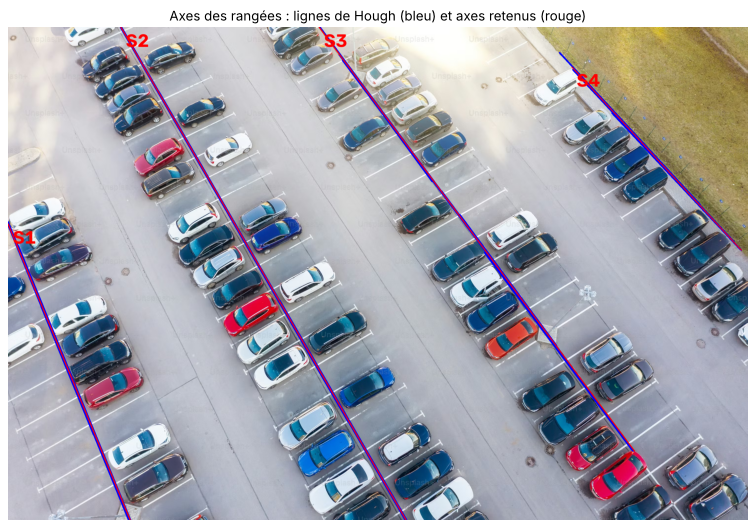

In [9]:
# --- Étape 1 : repérage automatique des longues lignes blanches (axes) ---
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
tophat = cv2.morphologyEx(gris, cv2.MORPH_TOPHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25)))
lignes_blanches = (((tophat > 35) & (S <= 80) & (V >= 140))).astype(np.uint8) * 255   # structures claires et fines, peu saturées
segs = cv2.HoughLinesP(lignes_blanches, 1, np.pi / 720, threshold=100, minLineLength=500, maxLineGap=40)
segs = [] if segs is None else segs.reshape(-1, 4)

# --- Axes retenus (extrémités en pixels, relevées sur ces longues lignes) ---
AXES = {
    "S1": ((0, 798),    (495, 1998)),
    "S2": ((458, 0),    (1614, 1998)),
    "S3": ((1262, 0),   (2541, 1719)),
    "S4": ((2287, 161), (2974, 904)),    # ligne le long de la bordure (places d'un seul côté)
}

vis = img.copy()
for x1, y1, x2, y2 in segs:
    ang = np.degrees(np.arctan2(y2 - y1, x2 - x1)) % 180
    if 40 <= ang <= 75:
        cv2.line(vis, (x1, y1), (x2, y2), (255, 0, 0), 6)           # Hough : bleu
for nom, (p0, p1) in AXES.items():
    cv2.line(vis, p0, p1, (0, 0, 255), 3)                            # axes retenus : rouge
    cv2.putText(vis, nom, (p0[0] + 20, p0[1] + 80), cv2.FONT_HERSHEY_SIMPLEX, 2.5, (0, 0, 255), 6)
print(f"{len(segs)} segments longs détectés par Hough")
afficher(vis, "Axes des rangées : lignes de Hough (bleu) et axes retenus (rouge)")

Nombre total de places définies : 119


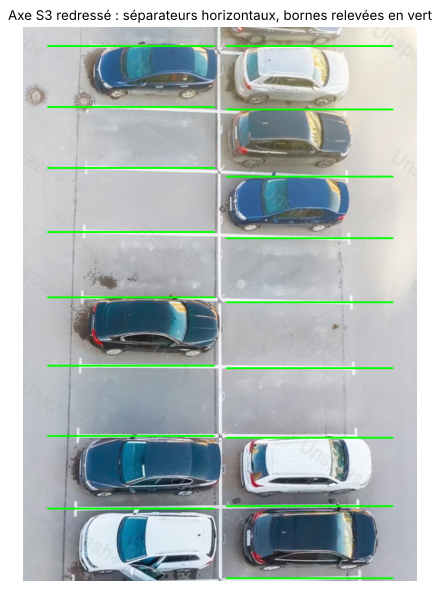

In [10]:
# --- Étape 2-4 : repère redressé et grille de places ---
DIVIDER_ANGLE_DEG = -30        # direction (image) des séparateurs de places : ~30° au-dessus de l'horizontale
W_DIR = np.array([np.cos(np.radians(DIVIDER_ANGLE_DEG)), np.sin(np.radians(DIVIDER_ANGLE_DEG))])  # (0.866, -0.5)
PROFONDEUR_PLACE = 275         # profondeur d'une place (px, le long des séparateurs)
DECALAGE_AXE = 8               # petite marge par rapport à la ligne d'axe

# Bornes t (position le long de l'axe, en pixels) des séparateurs : relevé manuel, une liste par rangée.
# 'L' = côté gauche de l'axe, 'R' = côté droit. Chaque paire de bornes consécutives = une place.
BORNES = {
    ("S1", "L"): [194, 303, 411, 522, 636, 752, 877, 1007, 1139],
    ("S1", "R"): [-17, 67, 186, 299, 410, 524, 622, 738, 881, 1009, 1140, 1278, 1371, 1483],
    ("S2", "L"): [-92, 34, 144, 231, 311, 412, 488, 583, 685, 784, 864, 991, 1112, 1225, 1342, 1463, 1563, 1733, 1825, 2008, 2113, 2219],
    ("S2", "R"): [164, 249, 334, 419, 529, 599, 715, 798, 900, 999, 1120, 1228, 1344, 1460, 1582, 1706, 1833, 1971, 2108, 2273, 2376, 2483],
    ("S3", "L"): [-86, -22, 54, 155, 244, 328, 431, 530, 629, 733, 839, 950, 1064, 1182, 1303, 1428, 1556, 1694, 1827, 1972, 2125, 2273, 2425],
    ("S3", "R"): [158, 252, 326, 431, 534, 643, 743, 847, 954, 1067, 1178, 1295, 1416, 1542, 1671, 1805, 1943, 2085, 2232, 2393, 2544],
    ("S4", "L"): [-210, -109, 2, 100, 202, 308, 417, 528, 643, 763, 885, 1012, 1144, 1246, 1389],
}

def point_image(axe, t, s):
    # (t, s) -> (x, y) : t le long de l'axe, s le long des séparateurs
    p0, p1 = np.array(AXES[axe], float)
    u = (p1 - p0) / np.linalg.norm(p1 - p0)
    return p0 + t * u + s * W_DIR

def quadrilatere(axe, cote, t0, t1):
    sg = 1 if cote == "R" else -1
    s_in, s_out = sg * DECALAGE_AXE, sg * PROFONDEUR_PLACE
    return np.array([point_image(axe, t0, s_in), point_image(axe, t1, s_in),
                     point_image(axe, t1, s_out), point_image(axe, t0, s_out)])

places = []
for (axe, cote), bornes in BORNES.items():
    for k, (t0, t1) in enumerate(zip(bornes, bornes[1:])):
        places.append({"axe": axe, "cote": cote, "k": k, "quad": quadrilatere(axe, cote, t0, t1), "occupee": False, "voiture": None})
print(f"Nombre total de places définies : {len(places)}")

def rectifier(axe, t_min, t_max, s_min=-320, s_max=320):
    # Image redressée : colonnes = s, lignes = t. Les séparateurs y sont horizontaux.
    p0, p1 = np.array(AXES[axe], float)
    u = (p1 - p0) / np.linalg.norm(p1 - p0)
    M = np.array([[W_DIR[0], u[0], p0[0] + t_min * u[0] + s_min * W_DIR[0]],
                  [W_DIR[1], u[1], p0[1] + t_min * u[1] + s_min * W_DIR[1]]])
    return cv2.warpAffine(img, M, (s_max - s_min, t_max - t_min), flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP)

# Vérification dans le repère redressé (axe S3) : les bornes doivent coller aux lignes blanches
t_min, t_max = 400, 1300
rect = rectifier("S3", t_min, t_max)
for cote in ("L", "R"):
    for t in BORNES[("S3", cote)]:
        if t_min <= t <= t_max:
            x0, x1 = (330, 600) if cote == "R" else (40, 310)
            cv2.line(rect, (x0, t - t_min), (x1, t - t_min), (0, 255, 0), 2)
plt.figure(figsize=(7, 9)); plt.imshow(cv2.cvtColor(rect, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("Axe S3 redressé : séparateurs horizontaux, bornes relevées en vert"); plt.show()

In [11]:
# --- Étape 5 : occupation des places avec les détections YOLO ---
def place_de(point):
    return [i for i, p in enumerate(places)
            if cv2.pointPolygonTest(p["quad"].astype(np.float32), (float(point[0]), float(point[1])), False) >= 0]

voitures_sans_place, voitures_multi = [], []
for v in voitures_parking:
    cand = place_de(v["centre"])
    if not cand:
        voitures_sans_place.append(v["id"])
        continue
    if len(cand) > 1:
        voitures_multi.append(v["id"])
    i = cand[0]
    places[i]["occupee"] = True
    places[i]["voiture"] = v["id"]

def fraction_visible(quad):
    # Part du quadrilatère qui se trouve dans l'image (certaines places sont coupées par le bord du cadre)
    marge, ech = 600, 4
    cv = np.zeros(((H_IMG + 2 * marge) // ech, (W_IMG + 2 * marge) // ech), np.uint8)
    pts = ((quad + marge) / ech).astype(np.int32)
    cv2.fillPoly(cv, [pts], 1)
    total = cv.sum()
    dedans = cv[marge // ech: (marge + H_IMG) // ech, marge // ech: (marge + W_IMG) // ech].sum()
    return dedans / max(total, 1)

for p in places:
    p["centre"] = p["quad"].mean(axis=0)
    p["visible"] = fraction_visible(p["quad"])

libres   = [p for p in places if not p["occupee"]]
occupees = [p for p in places if p["occupee"]]

# --- Contrôles de cohérence ---
print(f"Voitures dans le parking : {len(voitures_parking)}")
print(f"Places occupées          : {len(occupees)}")
print(f"Places libres            : {len(libres)}")
print(f"Places totales           : {len(places)}")
print("Voitures sans place :", voitures_sans_place, "| voitures à cheval sur 2 places :", voitures_multi)
assert not voitures_sans_place, "Une voiture n'est dans aucune place : vérifier BORNES / PROFONDEUR_PLACE"
assert not voitures_multi, "Une voiture est dans deux places à la fois"
assert len(occupees) == len(voitures_parking), "Incohérence : places occupées != voitures"
assert len(occupees) + len(libres) == len(places)
partielles = [(p["axe"], p["cote"], p["k"], round(p["visible"], 2)) for p in libres if p["visible"] < 0.6]
print("Places libres partiellement visibles (< 60 % dans l'image) :", partielles)
print("Cohérence vérifiée : places occupées = voitures dans le parking ; occupées + libres = total.")

Voitures dans le parking : 79
Places occupées          : 79
Places libres            : 40
Places totales           : 119
Voitures sans place : [] | voitures à cheval sur 2 places : []
Places libres partiellement visibles (< 60 % dans l'image) : [('S1', 'L', 1, np.float64(0.56))]
Cohérence vérifiée : places occupées = voitures dans le parking ; occupées + libres = total.


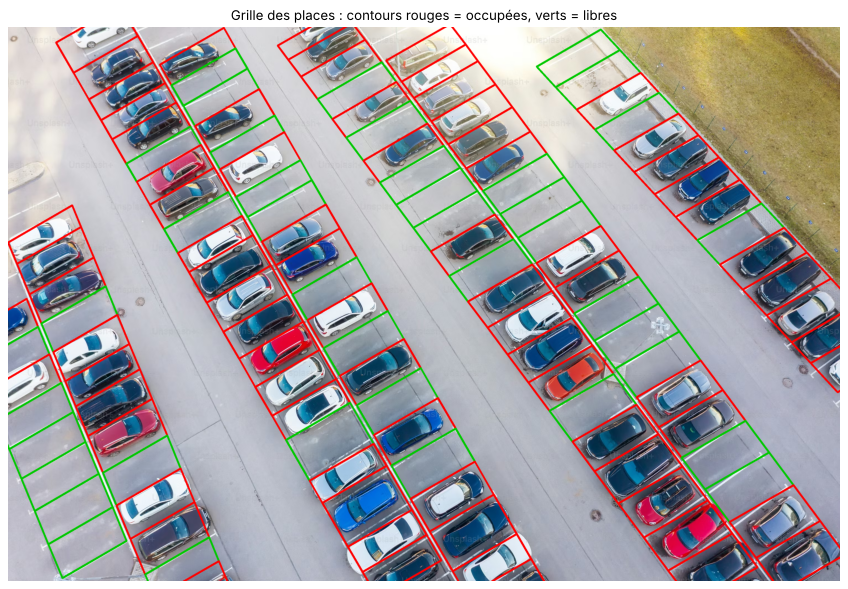

In [12]:
# Vérification visuelle de la grille : rouge = place occupée, vert = place libre
vis = img.copy()
for p in places:
    cv2.polylines(vis, [p["quad"].astype(np.int32)], True, (0, 0, 255) if p["occupee"] else (0, 200, 0), 5)
afficher(vis, "Grille des places : contours rouges = occupées, verts = libres", taille=(14, 9))

## 10. Visualisation des résultats finaux

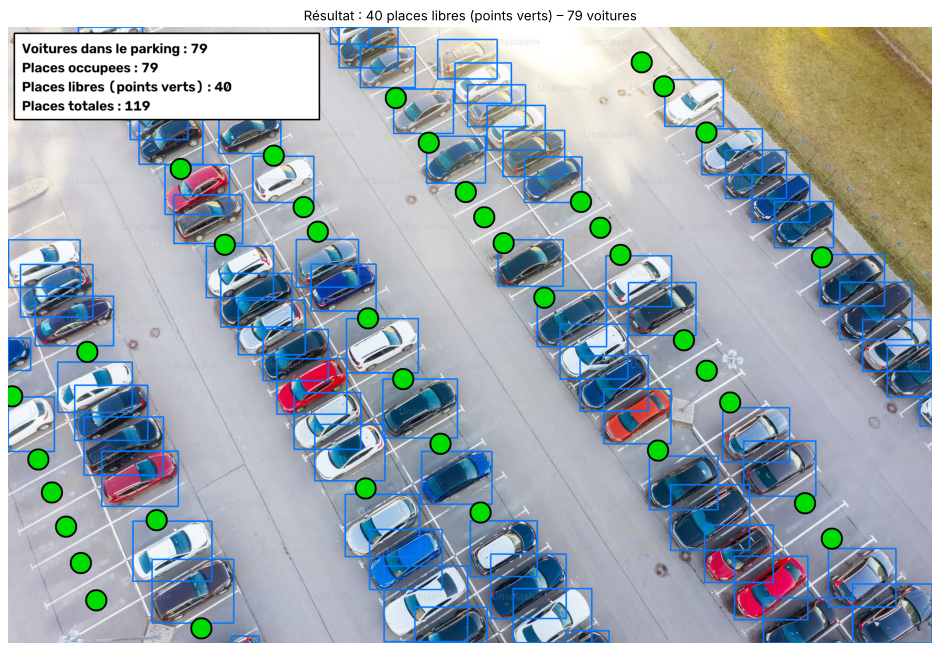

 Voitures dans le parking : 79
   dont rouges : 7 | blanches : 24 | noires : 22 | autres : 26
 Places totales           : 119
 Places occupées          : 79
 Places disponibles       : 40


In [13]:
final = img.copy()
for v in voitures_parking:                                   # voitures comptées
    x1, y1, x2, y2 = v["box"]
    cv2.rectangle(final, (x1, y1), (x2, y2), (255, 120, 0), 4)
for i, p in enumerate(libres, 1):                            # gros point vert sur chaque place libre
    cx, cy = int(p["centre"][0]), int(p["centre"][1])
    cv2.circle(final, (cx, cy), GREEN_DOT_RADIUS + 6, (0, 0, 0), -1)
    cv2.circle(final, (cx, cy), GREEN_DOT_RADIUS, (0, 220, 0), -1)

bandeau = [f"Voitures dans le parking : {len(voitures_parking)}",
           f"Places occupees : {len(occupees)}",
           f"Places libres (points verts) : {len(libres)}",
           f"Places totales : {len(places)}"]
cv2.rectangle(final, (20, 20), (1010, 300), (255, 255, 255), -1)
cv2.rectangle(final, (20, 20), (1010, 300), (0, 0, 0), 4)
for i, ligne in enumerate(bandeau):
    cv2.putText(final, ligne, (45, 85 + 62 * i), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 0), 3)
cv2.imwrite("resultat_final.png", final)
afficher(final, f"Résultat : {len(libres)} places libres (points verts) – {len(voitures_parking)} voitures", taille=(15, 10))

par_couleur = {c: sum(v["couleur"] == c for v in voitures_parking) for c in ("rouge", "blanc", "noir", "autre")}
print("=" * 52)
print(f" Voitures dans le parking : {len(voitures_parking)}")
print(f"   dont rouges : {par_couleur['rouge']} | blanches : {par_couleur['blanc']} | noires : {par_couleur['noir']} | autres : {par_couleur['autre']}")
print(f" Places totales           : {len(places)}")
print(f" Places occupées          : {len(occupees)}")
print(f" Places disponibles       : {len(libres)}")
print("=" * 52)

## 11. Conclusion et limites
**Résultats** : les chiffres ci-dessus sont calculés par le code (aucune valeur saisie à la main hormis la grille des places, détaillée en section 9).
Les voitures sont détectées par YOLO, classées par couleur en HSV, et rattachées à leur place ; les places sans voiture reçoivent un point vert.

**Limites à connaître (et à citer à l'oral)**
- **Couleurs** : la zone surexposée (reflet du soleil) et le **vernis noir qui reflète le ciel bleu** rendent la frontière noir / bleu foncé floue. Certaines voitures noires très éclairées peuvent tomber dans « autre », et quelques bleu foncé dans « noir » : le décompte des noires est approximatif. Les **gris/argent** tombent dans « autre » ou « blanc » selon l'éclairage. Les seuils HSV sont réglés pour **cette** image.
- **Grille des places** : les bornes sont relevées manuellement dans le repère redressé (délimitation permise par le sujet). Quand un véhicule masque un séparateur, la borne est complétée par le pas local : l'erreur est de quelques pixels et n'affecte pas l'occupation. Elle n'est pas transférable telle quelle à une autre image.
- **Places en bord de cadre** : quelques places libres sont coupées par le bord de l'image (voir la liste « partiellement visibles » en section 9) ; elles sont comptées car des lignes de marquage y sont visibles, mais leur existence complète est moins certaine.
- **Occupation** : on teste le **centre** de la boîte YOLO. Le toit d'une voiture est légèrement décalé par la perspective (parallaxe), d'où le test sur le centre plutôt que sur le recouvrement. Une voiture mal garée à cheval sur deux places serait attribuée à une seule.
- **Zone surexposée** (haut de l'image) : les lignes blanches y sont faiblement visibles ; les places libres proches de cette zone (haut, à droite) sont **moins certaines** et méritent une vérification visuelle.
- **YOLO** : modèle entraîné sur des vues majoritairement « de face » (COCO). Il fonctionne bien ici (confiance minimale ≈ 0,47) mais n'est pas garanti sur d'autres vues aériennes ; les boîtes se chevauchent car les voitures sont inclinées.

## 12. Justification théorique et préparation à l'oral

### Méthodes utilisées et fonctionnement
| Méthode | Fonctionnement | Pourquoi ici |
|---|---|---|
| **Espace HSV** | Sépare la **teinte** (H) de la **saturation** (S, pureté) et de la **valeur** (V, luminosité) | Rouge = teinte ; blanc = S faible + V fort ; noir = V faible. Seuils indépendants de l'éclairage (en partie) |
| **Morphologie** (ouverture / fermeture) | Ouverture = érosion puis dilatation (efface le bruit et les lignes fines) ; fermeture = l'inverse (comble les trous) | Supprime les lignes de marquage et les points isolés, comble vitres et reflets |
| **Composantes connexes + dilatation** | Regroupe les pixels voisins ; la dilatation élargit une zone | Isoler l'herbe, puis y rattacher la bordure |
| **YOLO** | Réseau de neurones convolutif qui prédit directement boîtes + classes + confiance en une passe | Détecte les voitures malgré les ombres, les reflets et l'orientation variable |
| **NMS** (suppression des non-maxima) | Garde la meilleure boîte parmi celles qui se recouvrent | Évite de compter deux fois la même voiture |
| **Transformation affine** (`warpAffine`) | Combinaison linéaire : rotation, cisaillement, échelle | Redresse les places en épi : les séparateurs deviennent horizontaux |
| **Hough probabiliste** | Vote dans l'espace des paramètres de droites | Repérer les longues lignes blanches des axes |
| **Test point-dans-polygone** | `pointPolygonTest` | Associer chaque voiture à une place, et à la zone parking |

### Justification des choix
- **Pourquoi HSV et pas RGB ?** En RGB, la luminosité est mélangée aux trois canaux : une voiture rouge à l'ombre et au soleil a des valeurs RGB très différentes. En HSV, sa **teinte reste proche**, seule V change.
- **Pourquoi deux intervalles pour le rouge ?** La teinte est un cercle : le rouge est autour de 0° donc se retrouve vers 0 **et** vers 179 en OpenCV.
- **Pourquoi YOLO ?** Les masques de couleur ne savent pas ce qu'est une voiture (le blanc capte aussi les lignes et le bitume surexposé). Un détecteur pré-entraîné localise les voitures sans réglage de seuils, et sans entraînement car COCO contient déjà la classe `car`.
- **Pourquoi `imgsz=1920` ?** Les voitures occupent peu de pixels par rapport à l'image 3000×1999 ; une résolution plus haute améliore le rappel.
- **Pourquoi redresser l'image pour les places ?** Les places sont inclinées et leur largeur varie avec la perspective. Dans le repère redressé, une place = un rectangle, ce qui rend le relevé et le test d'occupation simples et fiables.

### Logique des places disponibles
1. Définir toutes les places (quadrilatères délimités par les lignes blanches).
2. Pour chaque voiture dans le parking, trouver la place qui contient le **centre** de sa boîte → place **occupée**.
3. Les places sans voiture sont **libres** ; on y trace un point vert au **centre** du quadrilatère.
4. Contrôle : `places occupées = voitures dans le parking` et `occupées + libres = total`.

